# 05 – Neural network (MLP) + distillation (muon)

## 1. Introduction

Instead of formulas, here a **neural network** learns the shape, without a predefined functional form.
For every momentum, the network outputs a full probability map on the $(z', r)$ grid. It is trained with the same detector convolution and
likelihood as the cylinder formula (04), so the two are directly comparable.

**How does the MLP ("neural field") work?** The network is queried separately for every grid cell: *"what is the density at depth $z'$,
distance $r$, momentum $p$?"* The network's answers ($z'$, $r$, $\ln p$ and their sinusoidal features → $n_L$ hidden layers, $H$ neurons each → one number)
are turned into a probability map by a softmax. It acts like a **flexible, malleable map**: the network can take any smooth shape
the data demand.

**How large should the network be?** For the formulas, the degree of the $\ln p$ polynomial was chosen on the validation set (01, 4b). Here the same
protocol selects the **architecture**: several (layers, neurons) pairs are trained, and we keep the smallest one beyond which
larger networks no longer improve detectably (1-SE rule). This demonstrates that the network capacity is **sufficient**.

**Distillation (symbolic regression):** finally, the trained network is "translated" into an analytic formula: several formula families are fitted to the network maps,
and the simplest sufficiently accurate one is kept. This condenses the flexibility of the network into an interpretable formula with few parameters.

**Unified comparison (section 7):** at the end, the previous shapes (cylinder $r_{95}$) and the two new shapes
(MLP $r_{95}$, distilled formula $r_{95}$) are compared with the same metric and on the same plots as in notebook 03.

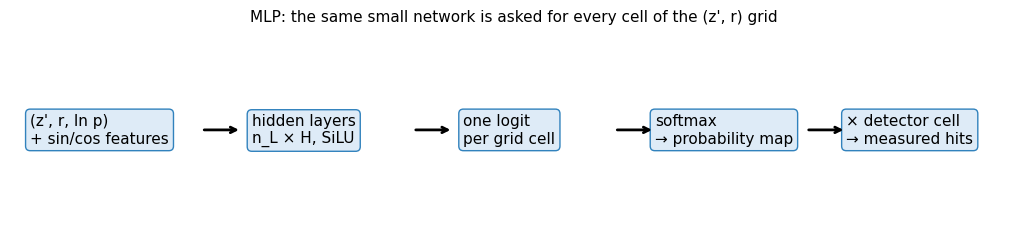

In [1]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(13, 2.6)); ax.axis("off")
boxes = [("(z', r, ln p)\n+ sin/cos features", 0.02), ("hidden layers\nn_L × H, SiLU", 0.24), ("one logit\nper grid cell", 0.45),
         ("softmax\n→ probability map", 0.64), ("× detector cell\n→ measured hits", 0.83)]
for txt, x in boxes:
    ax.text(x, 0.5, txt, ha="left", va="center", fontsize=11, bbox=dict(boxstyle="round", fc="#deebf7", ec="#3182bd"))
for x in (0.19, 0.40, 0.60, 0.79):
    ax.annotate("", xy=(x + 0.04, 0.5), xytext=(x, 0.5), arrowprops=dict(arrowstyle="->", lw=2))
ax.set_title("MLP: the same small network is asked for every cell of the (z', r) grid", fontsize=11)
plt.show()

## 2. Loading the data

In [2]:
PARTICLES = ['muon']
DATA_DIR = "../../data/simulations/regression-muon/"          # a CSV-k helye
OUT_DIR = "results"        # models and exports are stored here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-muon/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

muon: 99797 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69858, val 14969, test 14970

===== muon =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5067631 entries, 0 to 5067630
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                float6

,count,mean,std,min,25%,50%,75%,max
event_number,5067631.0,1.050881e+05,6.059986e+04,0.000000e+00,5.251400e+04,1.051720e+05,1.577220e+05,2.099970e+05
cellID,5067631.0,2.235442e+09,1.528754e+09,4.724000e+03,1.078464e+09,2.164590e+09,3.410281e+09,5.063386e+09
x,5067631.0,4.563739e+00,1.303354e+03,-2.596035e+03,-1.036428e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,5067631.0,7.028338e+00,1.307724e+03,-2.599800e+03,-1.036200e+03,2.620000e+01,1.036200e+03,2.599800e+03
z,5067631.0,4.215911e+03,3.512256e+02,3.662400e+03,3.908400e+03,4.195400e+03,4.502900e+03,4.871900e+03
x_local,5067631.0,-1.138769e+00,3.522868e+01,-2.312273e+03,-1.600449e+01,-1.002594e+00,1.390341e+01,1.703387e+03
y_local,5067631.0,-8.514499e-02,3.379383e+01,-1.721513e+03,-1.533235e+01,0.000000e+00,1.517229e+01,2.063125e+03
z_local,5067631.0,5.947941e+02,3.769971e+02,-1.132517e+03,2.676178e+02,5.697328e+02,9.091533e+02,1.623868e+03
x_trans,5067631.0,4.181690e-01,1.917018e+02,-2.706329e+03,-1.009449e+02,0.000000e+00,1.009449e+02,1.663381e+03
y_trans,5067631.0,8.447938e-01,1.920975e+02,-1.668400e+03,-1.010000e+02,0.000000e+00,1.010000e+02,2.186630e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,176421,5058537844,-1435.802002,1339.199951,4871.899902,9.502957,-23.063114,1309.566015,-355.508057,355.399963,...,0.000630,17.535614,3.817813,0.386266,2.402242,3,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
1,143783,1657341556,1949.927979,-935.200012,3826.399902,18.133007,-3.520068,198.721541,100.943970,-52.400024,...,0.000787,14.673748,13.625557,0.515130,-0.447856,13,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
2,143288,3326742132,1238.912964,-1339.199951,4195.399902,-0.587278,-0.951270,579.926957,153.619019,-169.200244,...,0.000567,15.240423,7.420113,0.406068,-0.829464,7,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,46874,2886257012,1791.905029,-834.200012,4789.899902,-11.030487,-16.424030,1214.374557,403.778076,-202.000000,...,0.000660,17.279598,17.166748,0.389733,-0.427482,17,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
4,165339,30024564,-878.405029,-1387.800049,3662.399902,-0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000640,13.388048,4.648698,0.419454,-2.145584,4,mu-,0,NaN,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...


## 3. The model

### What do we fit, and what affects training?

**Input:** only $\ln p$ (`incoming_momentum`); the network additionally receives the grid cell position ($z'$, $r$ and their sine/cosine features).
**Output:** the full $(z', r)$ map. Training minimises the same likelihood as for the formulas, so the fitted features are the same:
- $z'$ = `z_local`, $r$ = `hypot(x_local, y_local)`, weight `energy` (normalised per event), grouped by `event_number`.
- **Affected by:** the detector convolution (`incoming_theta`, `incoming_phi`, cell size), the back-face truncation ($z_b$ from the `z`, `z_trans` columns), the cuts.

**What differs from the formulas:**
- There is no prescribed functional form, so the shape is limited by **the grid resolution and the network architecture**. The number of layers ($n_L$) and
  neurons ($H$) are chosen in section 4; the number of frequencies is fixed (4).
- **Smoothness penalty** (`smooth=1e-4`): the second difference of $\log P$ along depth. It sets the "stiffness" of the network.
- **Beyond the back face** and **below the cell scale** the data do not constrain the network: there the output is set by the architecture and the penalty (artefacts are possible).
- Training: `epochs=60`, `lr=3e-3`, Adam, early stopping on the validation NLL (`patience=15`).

In [4]:
class FieldModel(nn.Module):
    """MLP(z', r, ln p) -> logit for every grid cell -> softmax."""

    def __init__(self, hidden=64, n_layers=3, n_freq=4):
        super().__init__()
        zn = (ZZ - Z_MIN) / (Z_MAX - Z_MIN) * 2 - 1          # depth scaled to [-1, 1]
        rn = torch.sqrt(RR / R_MAX)                            # radius, stretched near the axis
        feats = [zn, rn]
        for k in range(1, n_freq + 1):                         # sin/cos features: help to learn sharp structures
            feats += [torch.sin(math.pi * k * zn), torch.cos(math.pi * k * zn),
                      torch.sin(math.pi * k * rn), torch.cos(math.pi * k * rn)]
        self.register_buffer("static", torch.stack(feats, -1))
        layers, d = [], self.static.shape[-1] + 1
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        self.mlp = nn.Sequential(*layers, nn.Linear(d, 1))

    def forward(self, lnp):
        x = torch.cat([self.static[None].expand(len(lnp), -1, -1, -1),
                       (lnp / 3)[:, None, None, None].expand(-1, N_Z, N_R, 1)], -1)
        logits = self.mlp(x).squeeze(-1)
        return F.log_softmax(logits.reshape(len(lnp), -1), 1).reshape(len(lnp), N_Z, N_R)


make_model = lambda hidden=64, n_layers=3: FieldModel(hidden, n_layers).to(DEVICE)
arch_label = lambda cfg: f"L{cfg['n_layers']}xH{cfg['hidden']}"

print("parameters (L3xH64):", sum(p.numel() for p in make_model().parameters()))

parameters (L3xH64): 9665


## 4. Training and architecture selection

Same protocol as the degree selection for the formulas (common notebook, section 7, `select_architecture`):
- **train:** network weights; **validation:** early stopping and architecture selection; **test:** evaluation of the final network only.
- **Rule:** we compute the per-event paired difference relative to the architecture with the lowest validation NLL ($c^*$); the network with the **fewest
  parameters** whose difference is within one standard error is chosen.

The search has two stages (instead of a full grid, to save run time):
1. **Width:** $H \in \{16, 32, 64, 128, 256\}$, with 3 hidden layers.
2. **Depth (4b):** $n_L \in \{1, 2, 3, 4, 5\}$ with the chosen width.

Every network is saved to `results/muon/mlp_L<n_L>xH<H>.pt`; a completed training is only loaded.

**What to look for:** if the chosen network is at the **edge** of the range (largest $H$ or $n_L$), the search must be extended,
because sufficient capacity is not demonstrated. If it is inside and the curve flattens for larger networks, the capacity is saturated.

--- L3xH16 ---


loaded finished model from results/muon/mlp_L3xH16.pt


--- L3xH32 ---
loaded finished model from results/muon/mlp_L3xH32.pt


--- L3xH64 ---
loaded finished model from results/muon/mlp_L3xH64.pt


--- L3xH128 ---
loaded finished model from results/muon/mlp_L3xH128.pt


--- L3xH256 ---
loaded finished model from results/muon/mlp_L3xH256.pt


lowest validation NLL: L3xH32;  chosen by the 1-SE rule: L3xH32


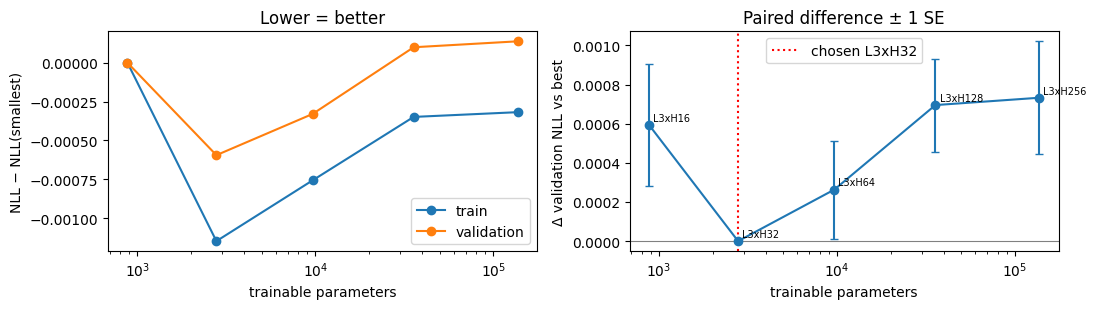

,n_layers,hidden,params,train NLL,val NLL,epochs,Δval vs best,SE,chosen
config,,,,,,,,,
L3xH16,3,16,881,16.0009,16.0031,44,0.0006,0.0003,
L3xH32,3,32,2785,15.9997,16.0025,57,0.0000,0.0000,◀
L3xH64,3,64,9665,16.0001,16.0028,58,0.0003,0.0002,
L3xH128,3,128,35713,16.0005,16.0032,51,0.0007,0.0002,
L3xH256,3,256,136961,16.0005,16.0033,51,0.0007,0.0003,


In [5]:
particle = "muon"
data = DATA[particle]
WIDTHS = [dict(n_layers=3, hidden=h) for h in (16, 32, 64, 128, 256)]
cfg_w, TAB_W, MODELS_W = select_architecture(make_model, WIDTHS, data, particle, "mlp", epochs=60, lr=3e-3, smooth=1e-4, label=arch_label)
display(TAB_W.round(4))

## 4b. Choosing the number of layers

With the chosen width, the number of layers is varied. The 3-layer network is loaded from the previous step.

--- L1xH32 ---
loaded finished model from results/muon/mlp_L1xH32.pt


--- L2xH32 ---
loaded finished model from results/muon/mlp_L2xH32.pt


--- L3xH32 ---
loaded finished model from results/muon/mlp_L3xH32.pt


--- L4xH32 ---
loaded finished model from results/muon/mlp_L4xH32.pt


--- L5xH32 ---
loaded finished model from results/muon/mlp_L5xH32.pt


lowest validation NLL: L4xH32;  chosen by the 1-SE rule: L3xH32


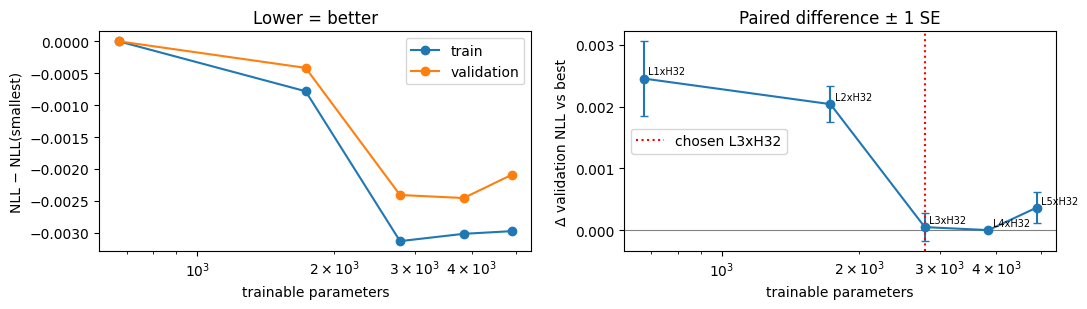

,n_layers,hidden,params,train NLL,val NLL,epochs,Δval vs best,SE,chosen
config,,,,,,,,,
L1xH32,1,32,673,16.0028,16.0049,60,0.0025,0.0006,
L2xH32,2,32,1729,16.0021,16.0045,57,0.0020,0.0003,
L3xH32,3,32,2785,15.9997,16.0025,57,0.0000,0.0002,◀
L4xH32,4,32,3841,15.9998,16.0025,43,0.0000,0.0000,
L5xH32,5,32,4897,15.9999,16.0028,57,0.0004,0.0003,


chosen architecture: L3xH32 | parameters: 2785 | inside the search range: capacity is sufficient


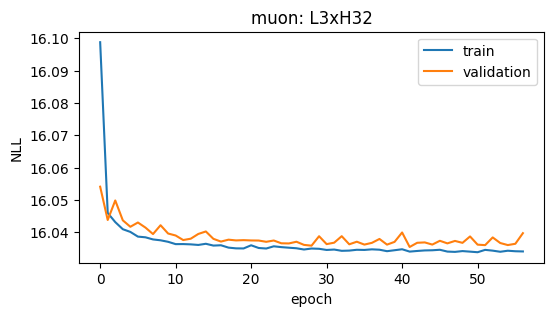

In [6]:
DEPTHS = [dict(n_layers=n, hidden=cfg_w["hidden"]) for n in (1, 2, 3, 4, 5)]
cfg, TAB_D, MODELS_D = select_architecture(make_model, DEPTHS, data, particle, "mlp", epochs=60, lr=3e-3, smooth=1e-4, label=arch_label)
display(TAB_D.round(4))
ARCH_TABLE = pd.concat([TAB_W.assign(stage="width"), TAB_D.assign(stage="depth")])
edge = cfg["hidden"] == max(c["hidden"] for c in WIDTHS) or cfg["n_layers"] == max(c["n_layers"] for c in DEPTHS)
print("chosen architecture:", arch_label(cfg), "| parameters:", int(TAB_D.loc[arch_label(cfg), "params"]),
      "| at the edge of the search range!" if edge else "| inside the search range: capacity is sufficient")

NETS = {particle: MODELS_D[arch_label(cfg)]}
hist = torch.load(f"{OUT_DIR}/{particle}/mlp_{arch_label(cfg)}.pt", weights_only=False)["history"]
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.title(f"{particle}: {arch_label(cfg)}"); plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 5. Distillation

Four formula families ($\{$`gamma`, `plateau`$\} \times \{$`core_tail`, `gauss_exp`$\}$) with first- and second-degree $\ln p$ dependence are fitted
to the maps of the chosen network. We keep the simplest one within 0.005 nat KL of the best.

**Here the formula is fitted to the network maps, not to the data** (KL divergence, 30 $\ln p$ values between the 2–98% quantiles of the training data, without convolution).
The map is used only up to depth $z_{cut}$ (still in front of the back face for 90% of training events). The formula quality is therefore also affected by the network's errors and
artefacts; the test NLL shows the result measured against the data. The result is saved to `results/muon/mlp_formula.pt`.

In [7]:
CANDIDATES = [("gamma", "core_tail"), ("gamma", "gauss_exp"), ("plateau", "core_tail"), ("plateau", "gauss_exp")]
FORMULAS = {}
for particle in PARTICLES:
    print(f"===== {particle} =====")
    path = f"{OUT_DIR}/{particle}/mlp_formula.pt"
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        f = Formula(ck["long"], ck["lat"], ck["degree"]).to(DEVICE)
        f.load_state_dict(ck["state"])
        print("loaded", path)
        display(ck["table"])
    else:
        f, table, z_cut = distill(NETS[particle], DATA[particle]["train"], CANDIDATES, steps=600)
        display(table.sort_values("KL"))
        torch.save({"long": f.long, "lat": f.lat, "degree": f.degree, "state": f.state_dict(), "table": table}, path)
    FORMULAS[particle] = f

===== muon =====
loaded results/muon/mlp_formula.pt


,longitudinal,lateral,degree,params,KL
0,gamma,core_tail,1,15,0.275333
1,gamma,core_tail,2,21,0.254377
2,gamma,gauss_exp,1,15,0.185770
3,gamma,gauss_exp,2,21,0.160843
4,plateau,core_tail,1,19,0.188906
5,plateau,core_tail,2,27,0.186247
6,plateau,gauss_exp,1,19,0.098465
7,plateau,gauss_exp,2,27,0.092287


## 6. Results

**What to look for:**
- **Test NLL:** whether the NLLs of the network and the formula are close. If so, the formula captures almost everything the network learned.
  Reference: the test NLL of the cylinder formula (04); the network must not be worse, otherwise it is not flexible enough or trained poorly.
- **Profiles:** both the network (orange) and the formula (red) should follow the data (black).
- **True shape and 3D:** whether the network shape is smooth. The network may learn small sub-cell artefacts (e.g. a thin spike on the axis),
  because the data do not constrain it there; the formula smooths these out.
- **Formula:** which family won, and how its parameters depend on momentum.

## muon

test NLL  cylinder (04): 16.0899
test NLL  mlp: 16.0046   formula: 16.0712   difference (paired): +0.0667 ± 0.0027


/tmp/ipykernel_324208/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### The distilled formula (plateau × gauss_exp, degree 2)

$$L \propto \sigma\!\left(\frac{z'-z_s}{w_1}\right)\sigma\!\left(\frac{\ell-z'}{w_2}\right)e^{\kappa z'/1000}$$

$$T = p_c\frac{e^{-r^2/2\sigma^2}}{2\pi\sigma^2}+(1-p_c)\frac{e^{-r/\lambda}}{2\pi\lambda^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `zs` | $-6.926 -0.2666\,L +0.05593\,L^2$ | – |
| `log_w1` | $+0.4087 -0.02544\,L +0.01252\,L^2$ | – |
| `log_ell` | $+6.784 +1.253\,L -0.07682\,L^2$ | – |
| `log_w2` | $+3.066 +0.504\,L +0.1327\,L^2$ | – |
| `kappa` | $-0.7226 -0.2105\,L +0.06371\,L^2$ | – |
| `log_sig` | $+2.751 -0.1166\,L +0.01357\,L^2$ | +0.3901 |
| `log_lam` | $+2.033 -0.3814\,L +0.3452\,L^2$ | +1.809 |
| `logit_pc` | $-0.06678 +3.41\,L -0.1878\,L^2$ | -2.275 |

Number of parameters: **27**

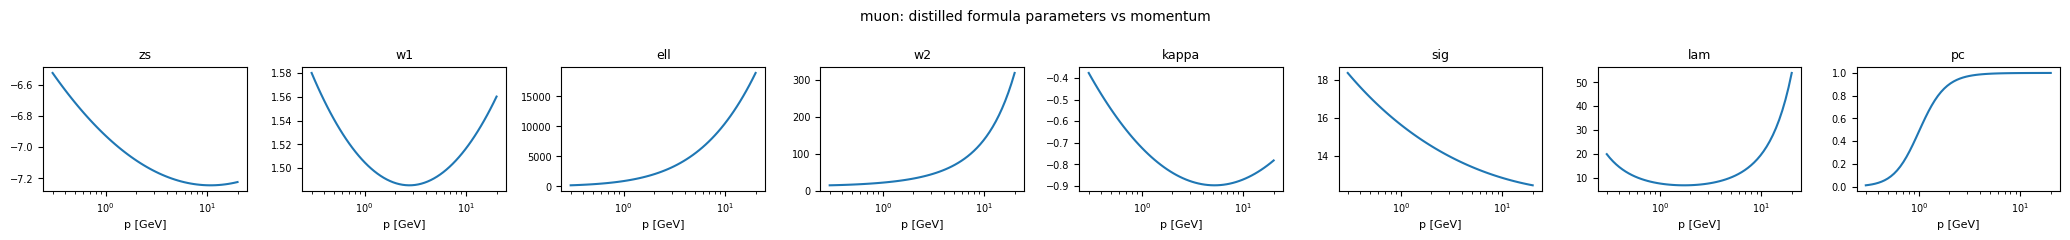

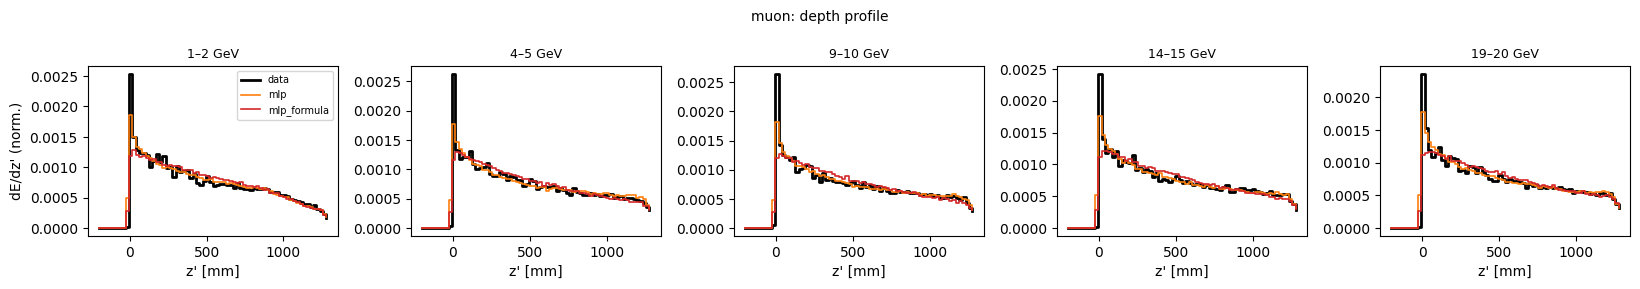

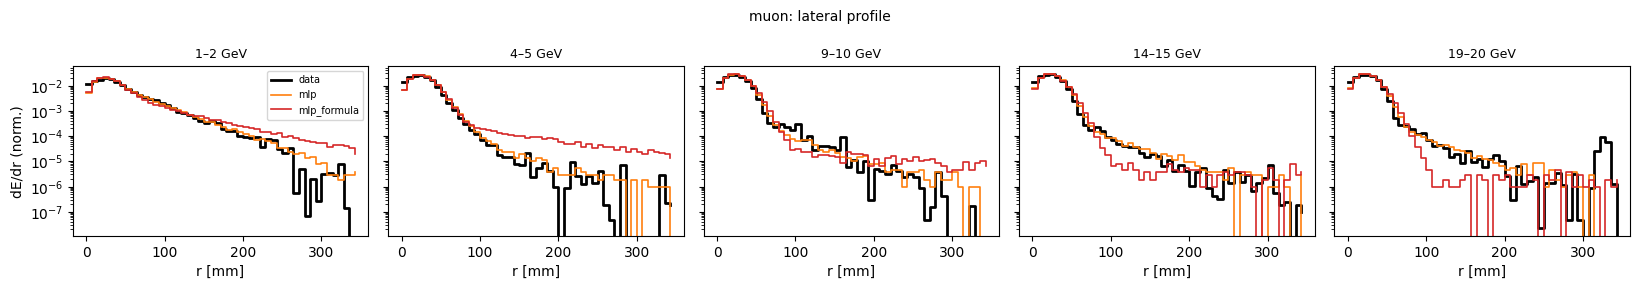

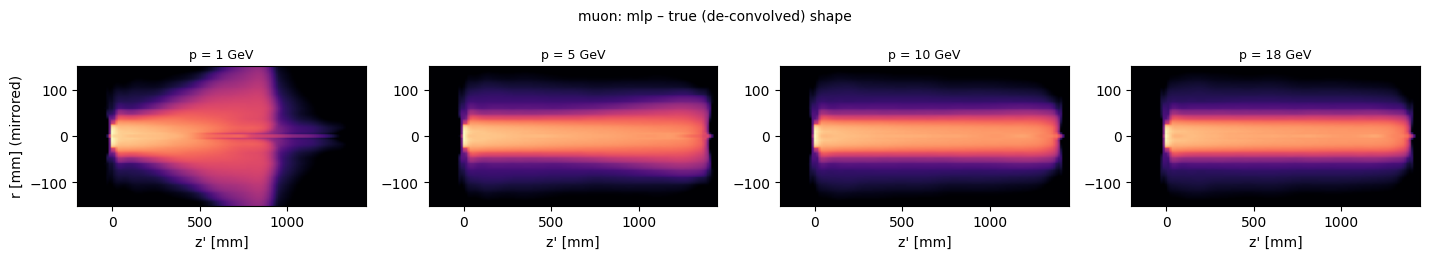

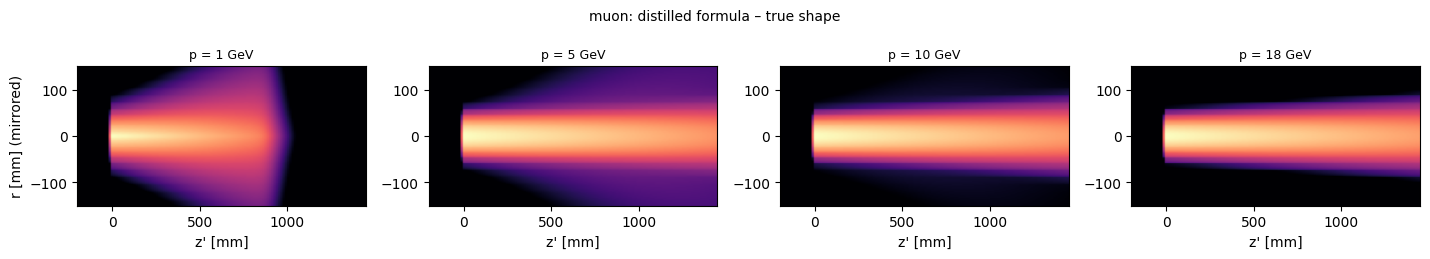

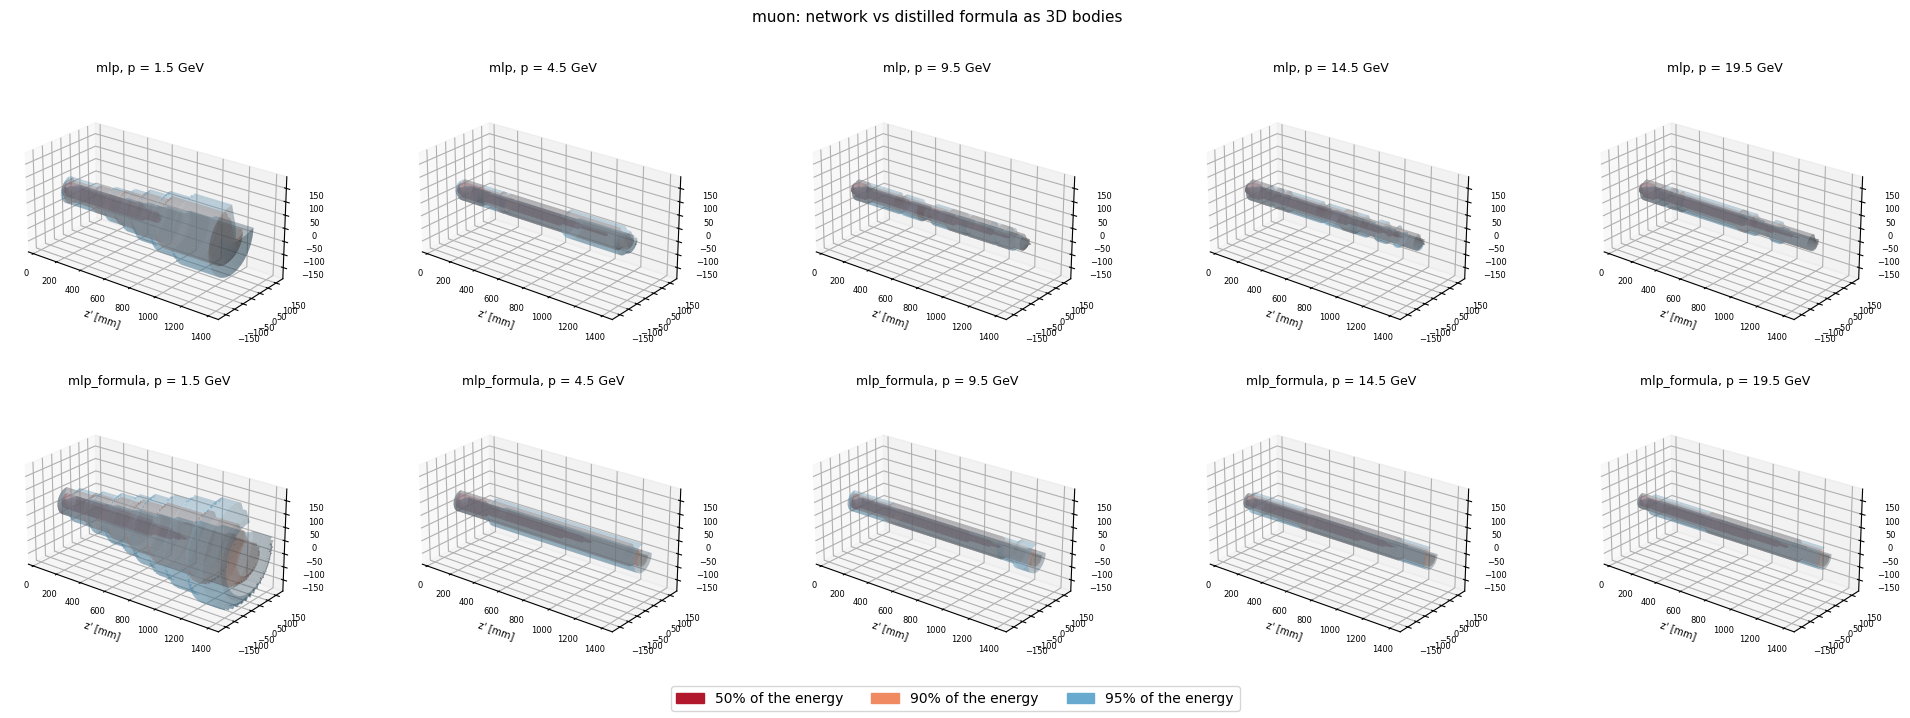

exported muon/mlp: test NLL = 16.0046
exported muon/mlp_formula: test NLL = 16.0712


In [8]:
for particle in PARTICLES:
    display(Markdown(f"## {particle}"))
    data, net, f = DATA[particle], NETS[particle], FORMULAS[particle]
    nll_net, nll_f = test_nll(net, data["test"]), test_nll(f, data["test"])
    gf_path = f"{OUT_DIR}/{particle}/export_cylinder.pt"
    if os.path.exists(gf_path):
        print(f"test NLL  cylinder (04): {torch.load(gf_path, weights_only=False)['test_nll'].mean():.4f}")
    d = nll_f - nll_net
    print(f"test NLL  mlp: {nll_net.mean():.4f}   formula: {nll_f.mean():.4f}   "
          f"difference (paired): {d.mean():+.4f} ± {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    display(Markdown(f.describe(f"The distilled formula ({f.long} × {f.lat}, degree {f.degree})")))
    formula_curves(f, f"{particle}: distilled formula parameters vs momentum")
    hits = data["test"].hits()
    samples = {"mlp": sample_folded(net, data["test"]), "mlp_formula": sample_folded(f, data["test"])}
    profile_plot(hits, samples, "z", f"{particle}: depth profile")
    profile_plot(hits, samples, "r", f"{particle}: lateral profile")
    shape_map(net, title=f"{particle}: mlp – true (de-convolved) shape")
    shape_map(f, title=f"{particle}: distilled formula – true shape")
    bodies_3d({"mlp": net, "mlp_formula": f}, title=f"{particle}: network vs distilled formula as 3D bodies")
    export(particle, "mlp", net, data)
    export(particle, "mlp_formula", f, data, f.describe(f"MLP → formula ({particle})"))

## 7. Unified comparison: three shapes with the same metric

Same metric and same plots as in the comparison of notebook 03, with two new shapes:

| | formula | what it describes | parameters |
|---|---|---|---|
| **Cylinder $r_{95}$** (04) | plateau × (core + tail) | 95% energy region of the **average** shower | ~15–60 (global) |
| **MLP $r_{95}$** (05) | neural field | 95% energy region of the **average** shower, without a fixed form | network weights (global) |
| **MLP-formula $r_{95}$** (05) | distilled formula | the same, with a formula extracted from the network | formula parameters (global) |

**Important for interpreting the metric:** the $r_{95}$ shapes (cylinder, network, formula) are 95% regions of the **average**, de-convolved shower; they were not built for the "95% in 98% of showers" criterion, whereas the envelopes were. Lower coverage and volume of the $r_{95}$ shapes is therefore expected and not a model failure. The volume of the envelope and the drop is the **analytic** volume of the whole body (the same quantity the fit minimises); for $r_{95}$ it is the volume summed on the grid (up to $Z_{MAX}$).

**Common metric in every 1 GeV bin:**
- **Volume** $V$ in litres (for the density models $V = \sum_{z'} \pi\, r_{95}(z')^2\, \Delta z'$ on the grid).
- **Test coverage:** fraction of test showers with at least 95% of their energy inside the shape (points spread within each cell).
  For muons there is no envelope or drop (a muon does not shower); the $r_{95}$ shapes describe the **average** shower, so their coverage is expected to be lower.
- **Thickest point** $z_{env}$ and **maximum radius** $r_{max}$.

The cylinder is loaded from `export_cylinder.pt`; if any is missing, run notebooks 01–04 first.

In [9]:
F_E, F_EV = 0.95, 0.98
G_MAX = 0.5 * 0.75 ** 1.5
zc, z_edges = ZC.cpu().numpy(), Z_EDGES.cpu().numpy()


def deposits(sh, K=8, seed=3):
    # Every hit -> K points inside its (rotated) cell, weight w/K (the same as in 02 and 03).
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def shower_quantile(P, s, f_e=F_E):
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def profile_coverage(P, radius_fn):
    # Fraction of showers keeping >= F_E of their energy inside r <= radius_fn(z').
    inside = torch.as_tensor(P["r"].cpu().numpy() <= radius_fn(P["z"].cpu().numpy()), device=DEVICE)
    s = torch.where(inside, torch.zeros_like(P["r"]), torch.full_like(P["r"], float("inf")))
    return float((shower_quantile(P, s) <= 0).float().mean())


def envelope_r(z, e):
    u = np.clip(np.asarray(z, dtype=float) - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def drop_radius(z, e):
    t = (np.asarray(z, dtype=float) - e["z0"]) / e["L"]
    return np.where((t > 0) & (t < 1), e["A"] * np.sqrt(np.clip(t, 0, 1)) * np.clip(1 - t, 0, 1) ** 1.5 / G_MAX, 0.0)


@torch.no_grad()
def r95_of(model, p):
    return iso_radius(model(torch.log(torch.tensor([p], device=DEVICE, dtype=torch.float32))).exp()[0].cpu().numpy(), F_E)


def grid_fn(r95):
    # step function on the (z', r) grid, as iso_radius defines it
    return lambda z: np.where((z >= Z_MIN) & (z < Z_MAX), r95[np.clip(np.searchsorted(z_edges, z) - 1, 0, len(r95) - 1)], 0.0)


def stats(radius_fn):
    zz = np.linspace(Z_MIN, Z_MAX, 3301)
    r = radius_fn(zz)
    return {"V_L": float(np.trapezoid(np.pi * r ** 2, zz)) / 1e6, "z_env": float(zz[np.argmax(r)]), "r_max": float(r.max())}


load = lambda name: torch.load(f"{OUT_DIR}/{particle}/{name}", weights_only=False) if os.path.exists(f"{OUT_DIR}/{particle}/{name}") else None
GF = TableModel(load("export_cylinder.pt")) if load("export_cylinder.pt") is not None else None
ENV, DROP = load("envelope.pt") or {}, load("drop.pt") or {}
MODELS = {"cylinder r95": GF, "MLP r95": NETS[particle], "MLP-formula r95": FORMULAS[particle]}
MODELS = {k: v for k, v in MODELS.items() if v is not None}
print("cylinder export:", GF is not None, "| envelope bins:", len(ENV), "| drop bins:", len(DROP))

rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    Pte = deposits(data["test"].subset(te))
    pm = float(data["test"].ev["p"][te].mean())
    shapes, grid = {}, {}
    for name, m in MODELS.items():
        grid[name] = r95_of(m, pm)
        shapes[name] = grid_fn(grid[name])
    if b in ENV:
        shapes["envelope"] = lambda z, e=ENV[b]: envelope_r(z, e)
    if b in DROP:
        shapes["drop"] = lambda z, e=DROP[b]: drop_radius(z, e)
    for name, fn in shapes.items():
        s = stats(fn)
        if name == "envelope":                                   # the analytic volume the fit minimises (whole body)
            s["V_L"] = ENV[b]["V_L"]
        if name == "drop":
            s["V_L"] = DROP[b]["V_L"]
        if name in grid:                                        # exact grid volume for the step profiles
            s["V_L"] = float(np.sum(np.pi * grid[name] ** 2) * DZ) / 1e6
        rows.append({"bin": b, "p_mean": pm, "formula": name, **s, "cov_test": profile_coverage(Pte, fn)})
CMP = pd.DataFrame(rows)
ORDER = ["cylinder r95", "envelope", "drop", "MLP r95", "MLP-formula r95"]
display(CMP.pivot(index="bin", columns="formula", values=["V_L", "cov_test"]).round(3))
summary = CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)])
summary["param"] = summary.index.map({"cylinder r95": f"{GF.n_params if GF is not None and hasattr(GF, 'n_params') else '~15–60'} (global)",
                                       "envelope": "4 / bin", "drop": "3 / bin",
                                       "MLP r95": f"{sum(p.numel() for p in NETS[particle].parameters())} (global)",
                                       "MLP-formula r95": f"{FORMULAS[particle].n_params()} (global)"})
display(summary.round(3))

cylinder export: True | envelope bins: 0 | drop bins: 0


V_L                              cov_test                  \
formula MLP r95 MLP-formula r95 cylinder r95  MLP r95 MLP-formula r95   
bin                                                                     
0         6.021           8.361       16.337    0.065           0.432   
1        37.270          76.779      136.318    0.412           0.851   
2        15.498          45.475       52.765    0.053           0.836   
3        10.569          19.486       34.920    0.013           0.575   
4         8.596          11.689       28.961    0.008           0.081   
5         7.623          10.018       25.979    0.001           0.013   
6         6.974           9.188       23.874    0.001           0.012   
7         6.769           8.634       22.383    0.003           0.015   
8         6.645           8.265       21.506    0.000           0.015   
9         6.552           8.034       20.892    0.000           0.015   
10        6.490           7.804       20.541    0.000           0.015   
11        6.429           7.665       20.278    0.001           0.008   
12        6.367           7.568       20.094    0.000           0.003   
13        6.336           7.506       19.899    0.001           0.016   
14        6.293           7.444       19.834    0.000           0.005   
15        6.262           7.414       19.769    0.000           0.008   
16        6.231           7.383       19.769    0.000           0.003   
17        6.231           7.352       19.769    0.000           0.004   
18        6.200           7.321       19.750    0.001           0.007   
19        6.169           7.321       19.815    0.001           0.005   

                      
formula cylinder r95  
bin                   
0              0.599  
1              0.964  
2              0.949  
3              0.963  
4              0.948  
5              0.896  
6              0.909  
7              0.899  
8              0.908  
9              0.887  
10             0.867  
11             0.899  
12             0.891  
13             0.901  
14             0.905  
15             0.903  
16             0.904  
17             0.912  
18             0.881  
19             0.896

,V_L,cov_test,z_env,r_max,param
formula,,,,,
cylinder r95,29.173,0.894,207.525,89.836,59 (global)
MLP r95,8.776,0.028,296.050,52.566,2785 (global)
MLP-formula r95,14.035,0.146,636.850,62.558,27 (global)


**What to look for in the table and plots:**
- **MLP $r_{95}$ vs. cylinder $r_{95}$:** both are the 95% region of the average shower. If they are close, the cylinder functional form is
  good enough; where they differ (e.g. shower start, lateral tail), the network learned something the formula cannot describe.
- **MLP-formula vs. MLP:** if the $r_{95}$ and coverage of the distilled formula are close to those of the network, distillation lost no essential information.


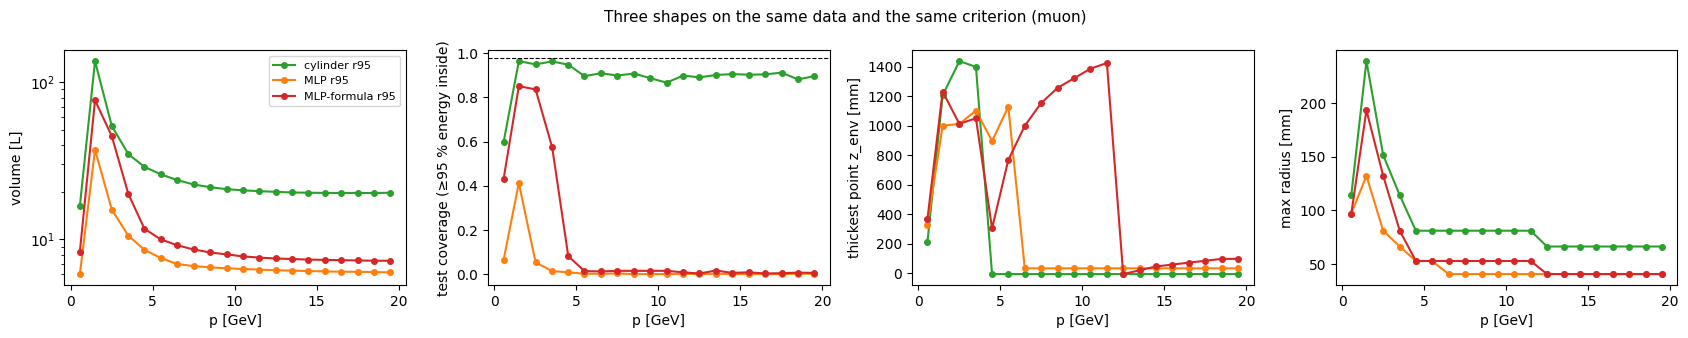

In [10]:
colors = {"cylinder r95": "tab:green", "envelope": "tab:blue", "drop": "tab:brown", "MLP r95": "tab:orange", "MLP-formula r95": "tab:red"}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for name in [o for o in ORDER if o in set(CMP.formula)]:
    g = CMP[CMP.formula == name]
    for a_, col in zip(ax, ["V_L", "cov_test", "z_env", "r_max"]):
        a_.plot(g.p_mean, g[col], "o-", c=colors[name], label=name, ms=4)
for a_, lab in zip(ax, ["volume [L]", "test coverage (≥95 % energy inside)", "thickest point z_env [mm]", "max radius [mm]"]):
    a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[1].axhline(F_EV, c="k", lw=0.8, ls="--"); ax[0].legend(fontsize=8)
fig.suptitle("Three shapes on the same data and the same criterion (muon)", fontsize=11)
plt.tight_layout(); plt.show()

### 2D map with $(z', r)$ axes, in the same form as the comparison plot of 03

- **Background:** mean energy density of the training data in the given 1 GeV bin ($\log_{10}$, $r$ mirrored).
- **Green dotted:** cylinder $r_{95}$. **Orange:** MLP $r_{95}$. **Red dashed:** distilled MLP-formula $r_{95}$.

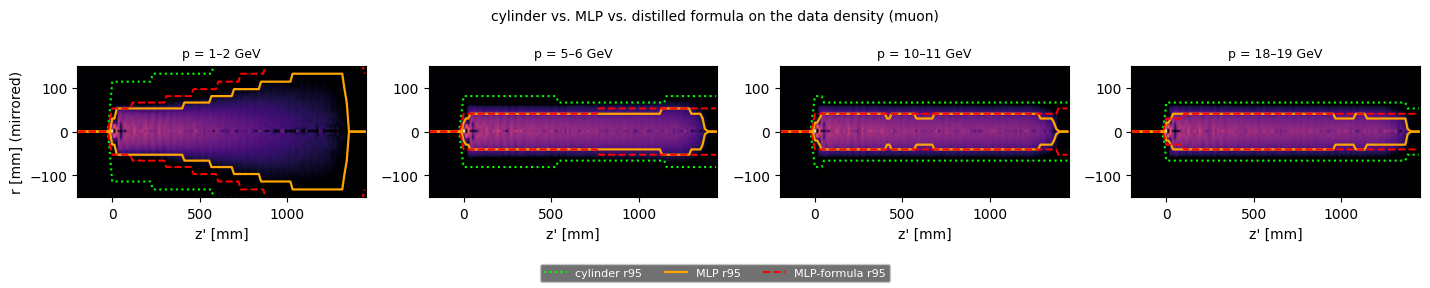

In [11]:
STYLE = {"cylinder r95": dict(c="lime", ls=":", lw=1.5), "envelope": dict(c="deepskyblue", lw=1.5), "drop": dict(c="white", lw=1.8),
         "MLP r95": dict(c="orange", lw=1.6), "MLP-formula r95": dict(c="red", ls="--", lw=1.4)}


def compare_map(sh, p_values=(1, 5, 10, 18), r_show=150, title=""):
    rc_ = RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.8))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[z_edges, R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc_, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        curves = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
        if b in ENV:
            curves["envelope"] = envelope_r(zc, ENV[b])
        if b in DROP:
            curves["drop"] = drop_radius(zc, DROP[b])
        for name in ORDER:
            if name in curves:
                ax.plot(zc, curves[name], **STYLE[name]); ax.plot(zc, -curves[name], **STYLE[name])
        ax.set_ylim(-r_show, r_show); ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9); ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], label=n, **STYLE[n]) for n in ORDER if n in set(CMP.formula)]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


compare_map(data["train"], title="cylinder vs. MLP vs. distilled formula on the data density (muon)")

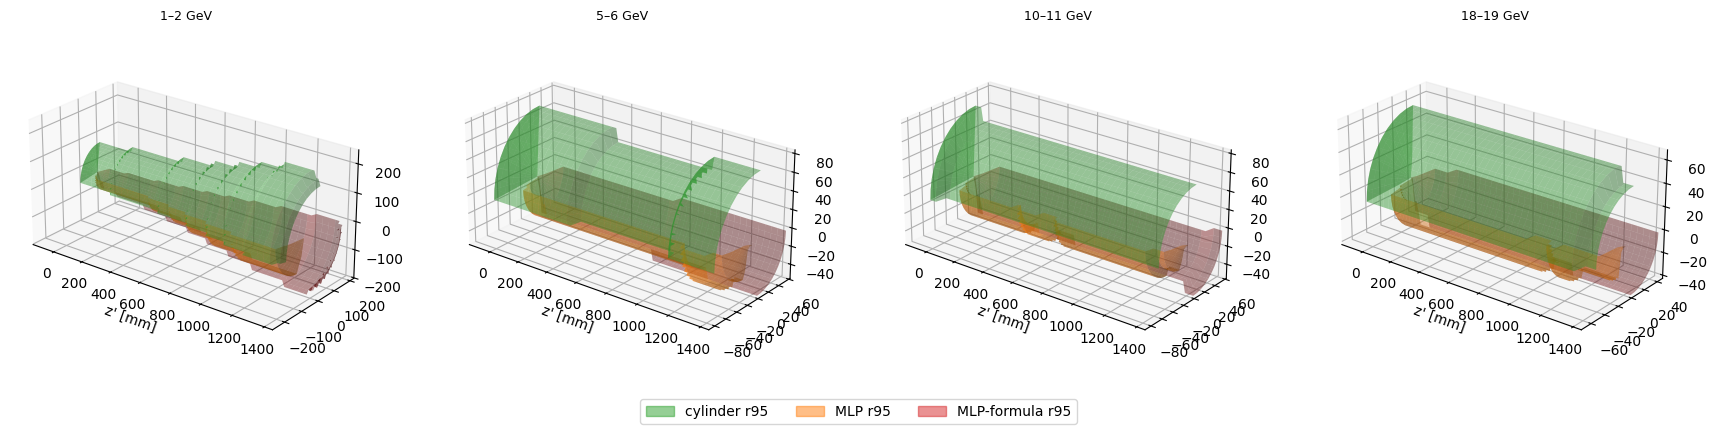

saved: comparison_5shapes.csv, mlp_architecture.csv


In [12]:
# the bodies side by side in 3D: each body in its own sector, so all of them stay visible
show = [1, 5, 10, 18]
fig = plt.figure(figsize=(4.4 * len(show), 4.2))
for j, b in enumerate(show):
    ax_ = fig.add_subplot(1, len(show), j + 1, projection="3d")
    bodies = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
    if b in ENV:
        bodies["envelope"] = envelope_r(zc, ENV[b])
    if b in DROP:
        bodies["drop"] = drop_radius(zc, DROP[b])
    names = [n for n in ORDER if n in bodies]
    for k, name in enumerate(names):
        f0 = 0.5 * np.pi + 1.5 * np.pi * k / len(names); f1 = 0.5 * np.pi + 1.5 * np.pi * (k + 1) / len(names)
        ax_.plot_surface(*revolve(zc, bodies[name], f0, f1, 12), color=colors[name], alpha=0.45, linewidth=0)
    ax_.set_xlim(-150, 1450); ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
    ax_.set_title(f"{b}–{b + 1} GeV", fontsize=9); ax_.set_xlabel("z' [mm]")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[n], alpha=0.5, label=n) for n in ORDER if n in set(CMP.formula)], loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
CMP.to_csv(f"{OUT_DIR}/{particle}/comparison_5shapes.csv", index=False)
ARCH_TABLE.to_csv(f"{OUT_DIR}/{particle}/mlp_architecture.csv")
print("saved: comparison_5shapes.csv, mlp_architecture.csv")